# Local Search & Optimization
## Hill-Climbing & Simulated Annealing


## Learning Objectives

By the end of this lab, you will be able to:

1. Explain how **Local Search** differs from the systematic search (BFS/DFS) covered last labs.
2. Implement **Hill-Climbing** and identify its main weakness: getting stuck at **local optima**.
3. Implement **Simulated Annealing** and explain how it uses **temperature** to escape local optima.
4. Compare the behavior of both algorithms on the same problem.


In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

## What is Local Search?

So far (BFS, DFS), we explored a search space **systematically**, keeping track of a frontier of states we hadn't visited yet, and we cared about the **path** from start to goal.

**Local Search** is different:

- It keeps track of only **one current state** (not a whole frontier).
- It moves to a **neighboring state** that looks better, and repeats.
- It does **not** care about the path taken, only about finding a state with a good (or the best possible) value.
- It is used for **optimization problems**: finding the state that **maximizes** or **minimizes** some objective function `f(x)`.

This makes local search ideal for problems where the state space is huge, such as scheduling, circuit design, or tuning parameters, problems where BFS/DFS would be far too slow or simply don't apply.

## Our Example Problem: Maximizing a Function

To keep things visual, we will use a 1D mathematical function `f(x)` with **multiple peaks (local maxima)** and try to find the **highest peak (global maximum)**.

$$ f(x) = \sin(x) + \sin(2.2x) $$

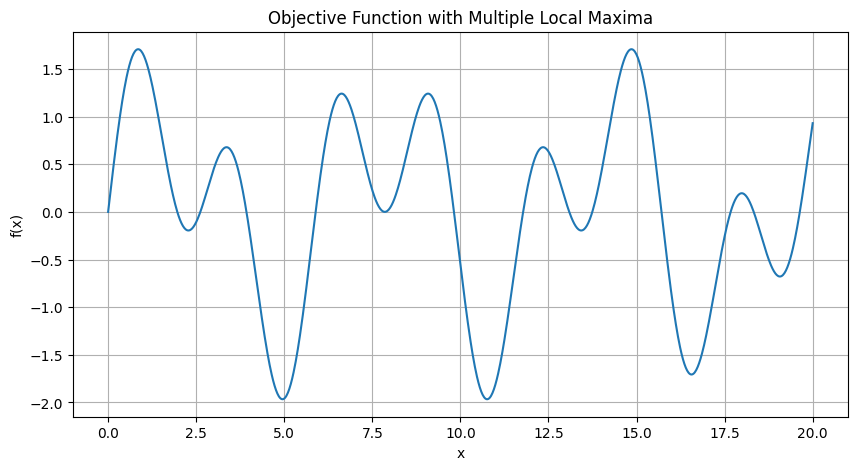

In [ ]:
def f(x):
    return np.sin(x) + np.sin(2.2 * x)

domain = (0, 20)

x_values = np.linspace(domain[0], domain[1], 1000)
y_values = f(x_values)

plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Objective Function with Multiple Local Maxima")
plt.grid(True)
plt.show()

## Hill-Climbing

 From the current state, look at its neighbors. Move to the best neighbor **if it's better than the current state**. Stop when no neighbor is better (you're at a peak).

This is like climbing a hill in thick fog, you can only feel the slope right around your feet, so you always step **uphill**, but you have no idea if a taller hill exists elsewhere.

### Hill-Climbing Algorithm (pseudocode)

```
Hill-Climbing(f, start):
    current = start
    loop:
        neighbor = best neighbor of current
        
        if f(neighbor) <= f(current):
            return current          # no improvement possible — stop
        current = neighbor
```

### Key Weakness: Local Optima

Hill-Climbing always moves uphill, so once it reaches the top of **any** hill, even a small one, it stops. It has no way of knowing a taller hill exists elsewhere, since it only looks at its immediate neighbors.

In [ ]:
def get_best_neighbor(f, x, step, domain):
    """Return whichever of (x - step, x + step) has the higher f-value, staying in-domain."""
    candidates = [x - step, x + step]
    candidates = [c for c in candidates if domain[0] <= c <= domain[1]]
    best = max(candidates, key=f)
    return best


def hill_climbing(f, start, step, domain, max_iterations=1000):

    current = start
    path = [current]

    for _ in range(max_iterations):
        neighbor = get_best_neighbor(f, current, step, domain)
        if f(neighbor) <= f(current):
            break
        current = neighbor
        path.append(current)

    return current, f(current), path

Started at x = 10.0
Hill-Climbing stopped at x = 9.100, f(x) = 1.240


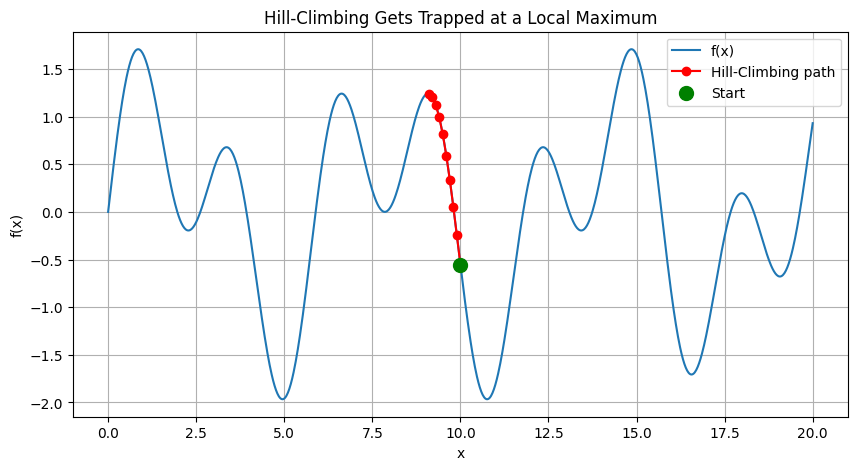

In [ ]:
# Run Hill-Climbing from a starting point that gets trapped in a small local hill
start_x = 10.0
result_x, result_val, path = hill_climbing(f, start_x, step=0.1, domain=domain)

print(f"Started at x = {start_x}")
print(f"Hill-Climbing stopped at x = {result_x:.3f}, f(x) = {result_val:.3f}")

plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label="f(x)")
plt.plot(path, [f(p) for p in path], 'ro-', label="Hill-Climbing path")
plt.scatter([start_x], [f(start_x)], color='green', s=100, zorder=5, label="Start")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Hill-Climbing Gets Trapped at a Local Maximum")
plt.legend()
plt.grid(True)
plt.show()

Notice that Hill-Climbing stopped at a **local** maximum, even though a much better (global) peak exists elsewhere on the curve. This is exactly the weakness Simulated Annealing is designed to fix.

### 📝 Practice Cell (Hill-Climbing)

Try re-running Hill-Climbing from a few different `start_x` values (e.g., `2.0`, `5.0`, `15.0`, `18.0`). Which starting points reach the global maximum, and which get trapped?


In [ ]:
# Your practice code here



## Simulated Annealing

Simulated Annealing (SA) works like Hill-Climbing, but with one crucial twist: it sometimes accepts a **worse** move, especially early on. This lets it escape small local hills and keep searching for a better one.

The name comes from **annealing** in metallurgy: a metal is heated and then slowly cooled, allowing its atoms to settle into a low-energy, stable arrangement. Here, a **temperature** parameter `T` controls how often we accept worse moves:

- **High temperature (early):** We accept worse moves often — lots of exploration.
- **Low temperature (late):** We accept worse moves rarely — the search behaves more like plain Hill-Climbing, settling into a good spot.

### Acceptance Rule

Given the current state's value and a candidate neighbor's value, let `Δ = f(candidate) − f(current)`:

- If `Δ > 0` (candidate is better): **always accept**.
- If `Δ ≤ 0` (candidate is worse): accept anyway with probability
  $$ P = e^{\Delta / T} $$

As `T` decreases over time (the **cooling schedule**), this probability shrinks, so the algorithm gradually settles down.

### Simulated Annealing Algorithm (pseudocode)

```
Simulated-Annealing(f, start, T, cooling_rate):
    current = start
    loop until T is very small:
        candidate = a random neighbor of current
        delta = f(candidate) - f(current)
        if delta > 0 or random() < exp(delta / T):
            current = candidate
        T = T * cooling_rate
    return best state found
```

In [ ]:
def simulated_annealing(f, start, domain, initial_temp=10.0, cooling_rate=0.995,
                         step=0.5, iterations=2000):

    current = start
    current_val = f(current)
    best, best_val = current, current_val
    temp = initial_temp
    path = [current]

    for _ in range(iterations):
        candidate = current + random.uniform(-step, step)
        candidate = min(max(candidate, domain[0]), domain[1])  # stay inside the domain
        candidate_val = f(candidate)

        delta = candidate_val - current_val
        if delta > 0 or random.random() < np.exp(delta / temp):
            current, current_val = candidate, candidate_val
            if current_val > best_val:
                best, best_val = current, current_val

        temp *= cooling_rate
        path.append(current)

    return best, best_val, path

Started at x = 10.0
Simulated Annealing found x = 0.852, f(x) = 1.707


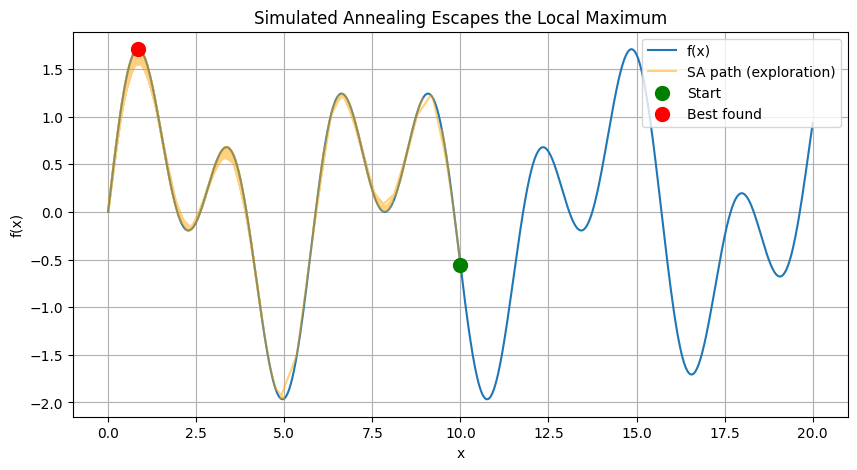

In [ ]:
# Run Simulated Annealing from the SAME trapped starting point as Hill-Climbing
random.seed(7)
best_x, best_val, sa_path = simulated_annealing(f, start_x, domain)

print(f"Started at x = {start_x}")
print(f"Simulated Annealing found x = {best_x:.3f}, f(x) = {best_val:.3f}")

plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label="f(x)")
plt.plot(sa_path, [f(p) for p in sa_path], color='orange', alpha=0.5, label="SA path (exploration)")
plt.scatter([start_x], [f(start_x)], color='green', s=100, zorder=5, label="Start")
plt.scatter([best_x], [best_val], color='red', s=100, zorder=5, label="Best found")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Simulated Annealing Escapes the Local Maximum")
plt.legend()
plt.grid(True)
plt.show()

From the **same starting point** that trapped Hill-Climbing, Simulated Annealing was able to explore past the small local hill and find a much better peak because early on (high temperature), it was willing to accept some worse moves instead of only climbing straight up.

### 📝 Practice Cell (Simulated Annealing)

Try changing `initial_temp` and `cooling_rate` in the cell above (e.g., `cooling_rate=0.999` for slower cooling, or `initial_temp=1.0` for less exploration). How does this affect whether SA finds the global maximum?


In [ ]:
# Your practice code here



## Hill-Climbing vs Simulated Annealing

| Feature | Hill-Climbing | Simulated Annealing |
|---|---|---|
| Moves to worse states? | Never | Sometimes (probability depends on `T`) |
| Risk of local optima | High | Lower (can escape, not guaranteed) |
| Extra parameters | None | Initial temperature, cooling rate |
| Speed | Fast — stops as soon as no improvement | Slower — runs for a fixed number of iterations |
| Guaranteed optimal? | No | No, but more likely in practice |

### Quick Reflection Questions

1. Why does Simulated Annealing become more like plain Hill-Climbing as `T → 0`?
2. What might happen if the cooling rate is too fast (temperature drops to ~0 very quickly)?
3. What might happen if the cooling rate is too slow (temperature stays high for too long)?